## **FINSIR: prueba del modelo con muestra de clientes**

Este notebook lee los Parquet Gold existentes directamente desde `s3://bucket/gold/train/`. DuckDB filtra las particiones por fecha y selecciona aproximadamente el 10 % de los clientes con un hash determinista de `ncodpers`, conservando todas las filas mensuales de cada cliente seleccionado.

El resultado de la consulta se materializa en pandas solo después de filtrar la muestra. Esta versión sirve para desarrollar y comparar el pipeline, antes del despliegue final, se debe ejecutar con todos los clientes y volver a medir MAP@7.

**Cortes:** entrenamiento hasta febrero de 2016, validación marzo (adquisiciones de abril), prueba abril (adquisiciones de mayo). Mayo se reserva para generar predicciones de junio.

### **1. Dependencias**

In [1]:
# %pip install --upgrade "duckdb>=1.4" boto3 pandas lightgbm scikit-learn matplotlib seaborn joblib

### **2. Configuración y credenciales AWS**

El perfil `terraform` debe existir en AWS CLI y tener permiso de lectura para `s3://bucket/gold/train/`. Si el perfil es SSO y expiró, ejecutar `aws sso login --profile terraform` en una terminal.

In [2]:
from pathlib import Path
import boto3
import duckdb
import pandas as pd

AWS_PROFILE = "terraform"
AWS_REGION = "us-east-1"

aws_session = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION)
identity = aws_session.client("sts").get_caller_identity()

BUCKET = f"finsir-{identity['Account']}"
GOLD_GLOB = f"s3://{BUCKET}/gold/train/**/*.parquet"
START_DATE = "2015-07-28"  
END_DATE = "2016-05-28"
SAMPLE_MODULUS = 10  # hash(ncodpers) % 10 = 0: aprox. 10% de clientes

aws_session = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION)
identity = aws_session.client("sts").get_caller_identity()
print(f"Cuenta AWS: {identity['Account']} | region: {AWS_REGION}")
print(f"Fuente Gold: {GOLD_GLOB}")


Cuenta AWS: 670099380322 | region: us-east-1
Fuente Gold: s3://finsir-670099380322/gold/train/**/*.parquet


### **3. Leer y muestrear directamente desde S3**

DuckDB lee los Parquet desde S3, aplica el rango temporal y filtra por hash de cliente antes de entregar las filas a pandas. La selección es aproximadamente 10 % y es consistente en todos los meses para el mismo `ncodpers`.

In [3]:
print('---')
con = duckdb.connect()
con.execute("INSTALL aws")
con.execute("LOAD aws")
con.execute("INSTALL httpfs")
con.execute("LOAD httpfs")
con.execute(f"""
    CREATE OR REPLACE SECRET finsir_s3 (
        TYPE s3,
        PROVIDER credential_chain,
        CHAIN config,
        PROFILE '{AWS_PROFILE}',
        REGION '{AWS_REGION}'
    )
""")

sample_sql = f"""
SELECT *
FROM read_parquet('{GOLD_GLOB}', hive_partitioning = true, union_by_name = true)
WHERE CAST(fecha_dato AS VARCHAR) BETWEEN '{START_DATE}' AND '{END_DATE}'
  AND hash(ncodpers) % {SAMPLE_MODULUS} = 0
"""

df = con.execute(sample_sql).fetchdf()
print(f"Filas muestreadas: {len(df):,}")
print(f"Clientes muestreados: {df['ncodpers'].nunique():,}")
print(f"Meses: {df['fecha_dato'].nunique()}")
df.head()

---


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Filas muestreadas: 992,301
Clientes muestreados: 95,426
Meses: 11


,ncodpers,month_of_year,ind_empleado,pais_residencia,sexo,age,antiguedad,ind_nuevo,indrel,indrel_1mes,...,label_next_ind_pres_fin_ult1,label_next_ind_reca_fin_ult1,label_next_ind_tjcr_fin_ult1,label_next_ind_valo_fin_ult1,label_next_ind_viv_fin_ult1,label_next_ind_nomina_ult1,label_next_ind_nom_pens_ult1,label_next_ind_recibo_ult1,label_next_n_added,fecha_dato
0,17381,7,N,ES,V,44,216,0,1,1,...,0,0,0,0,0,0,0,0,0,2015-07-28
1,18282,7,N,ES,H,80,242,0,1,1,...,0,0,0,0,0,0,0,0,0,2015-07-28
2,19420,7,N,ES,V,72,169,0,1,1,...,0,0,0,0,0,0,0,0,0,2015-07-28
3,20077,7,N,ES,V,49,228,0,1,1,...,0,0,0,0,0,0,0,0,0,2015-07-28
4,21201,7,N,ES,H,47,236,0,1,1,...,0,0,0,0,0,0,0,0,0,2015-07-28


### **4. EDA y preparación de cortes**

Las etiquetas `label_next_*` están definidas en Gold para el mes siguiente. Las filas sin etiquetas completas no sirven para entrenar o evaluar, mayo se mantiene aparte para inferencia.


In [4]:
LABEL_PREFIX = "label_next_"
label_cols = sorted(c for c in df.columns if c.startswith(LABEL_PREFIX) and c != "label_next_n_added")
products = [c[len(LABEL_PREFIX):] for c in label_cols]
assert len(products) == 24, f"Se esperaban 24 productos, hay {len(products)}"
assert all(p in df.columns for p in products)

df["fecha_dato"] = pd.to_datetime(df["fecha_dato"])
labeled = df.loc[df[label_cols].notna().all(axis=1)].copy()
summary = pd.DataFrame({"adopciones": labeled[label_cols].sum().values}, index=products)
summary["tasa_por_fila"] = summary["adopciones"] / len(labeled)
display(summary.sort_values("adopciones", ascending=False))

train = labeled.loc[(labeled.fecha_dato >= "2015-07-28") & (labeled.fecha_dato <= "2016-02-28")].copy()
valid = labeled.loc[labeled.fecha_dato == "2016-03-28"].copy()
test = labeled.loc[labeled.fecha_dato == "2016-04-28"].copy()
may = df.loc[df.fecha_dato == "2016-05-28"].copy()
print(f"Train {len(train):,} | validacion {len(valid):,} | prueba {len(test):,} | mayo para inferencia {len(may):,}")
assert len(train) and len(valid) and len(test) and len(may), "Falta algun corte mensual esperado"


,adopciones,tasa_por_fila
ind_recibo_ult1,10224,0.0114
ind_nom_pens_ult1,5190,0.005787
ind_cco_fin_ult1,5113,0.005701
ind_nomina_ult1,4755,0.005302
ind_tjcr_fin_ult1,4358,0.004859
ind_cno_fin_ult1,2505,0.002793
ind_ecue_fin_ult1,1836,0.002047
ind_dela_fin_ult1,726,0.00081
ind_ctma_fin_ult1,564,0.000629
ind_reca_fin_ult1,377,0.00042


Train 710,756 | validacion 92,873 | prueba 93,201 | mayo para inferencia 93,640


### **5. Métrica MAP@7 y baseline de popularidad**

El baseline ordena los productos por su frecuencia de adopción en entrenamiento. Para cada cliente excluye los productos que ya posee.

In [5]:
K = 7

def average_precision_at_k(actual, predicted, k=K):
    actual = set(actual)
    if not actual:
        return 0.0
    hits, score, seen = 0, 0.0, set()
    for rank, product in enumerate(predicted[:k], start=1):
        if product in actual and product not in seen:
            hits += 1
            score += hits / rank
            seen.add(product)
    return score / min(len(actual), k)

def map_at_7(frame, scores, k=K):
    values = []
    for idx, row in frame.iterrows():
        if row[label_cols].isna().any():
            continue
        actual = [p for p in products if row[f"{LABEL_PREFIX}{p}"] == 1]
        held = {p for p in products if pd.notna(row[p]) and row[p] == 1}
        ranked = sorted(products, key=lambda p: (-float(scores.at[idx, p]), p))
        predicted = [p for p in ranked if p not in held][:k]
        values.append(average_precision_at_k(actual, predicted, k))
    if not values:
        raise ValueError("No hay filas etiquetadas para calcular MAP@7")
    return sum(values) / len(values)

def popularity_scores(reference, target):
    rates = {}
    for p in products:
        eligible = reference[p].fillna(0).eq(0) & reference[f"{LABEL_PREFIX}{p}"].notna()
        rates[p] = reference.loc[eligible, f"{LABEL_PREFIX}{p}"].mean() if eligible.any() else 0.0
    return pd.DataFrame({p: rates[p] for p in products}, index=target.index), pd.Series(rates, name="tasa_adopcion")

valid_pop, popularity = popularity_scores(train, valid)
test_pop, _ = popularity_scores(train, test)
print(f"Popularidad - validacion MAP@7: {map_at_7(valid, valid_pop):.6f}")
print(f"Popularidad - prueba MAP@7: {map_at_7(test, test_pop):.6f}")
display(popularity.sort_values(ascending=False).to_frame())


Popularidad - validacion MAP@7: 0.018832
Popularidad - prueba MAP@7: 0.019569


,tasa_adopcion
ind_cco_fin_ult1,0.015544
ind_recibo_ult1,0.013107
ind_nom_pens_ult1,0.006265
ind_nomina_ult1,0.005706
ind_tjcr_fin_ult1,0.005125
ind_cno_fin_ult1,0.003051
ind_ecue_fin_ult1,0.002008
ind_dela_fin_ult1,0.001043
ind_ctma_fin_ult1,0.000634
ind_valo_fin_ult1,0.000484


### **6. Entrenar LightGBM por producto**

Cada producto es un problema binario independiente. Solo se entrena con clientes elegibles que aún no poseen ese producto, se excluyen todas las etiquetas de las features. Marzo se usa para early stopping.

In [13]:
print("---")

import lightgbm as lgb

feature_cols = [c for c in df.columns if not c.startswith(LABEL_PREFIX) and c not in {"ncodpers", "fecha_dato"}]
assert not any(c.startswith(LABEL_PREFIX) for c in feature_cols)
def align_categories(values, categories):
    """Valores no vistos en train pasan a NA antes de fijar las categor?as."""
    values = values.astype("object")
    known_or_missing = values.isna() | values.isin(categories)
    return pd.Categorical(values.where(known_or_missing), categories=categories)

models = {}
valid_model = pd.DataFrame(0.0, index=valid.index, columns=products)
test_model = pd.DataFrame(0.0, index=test.index, columns=products)
importance = []

for number, p in enumerate(products, start=1):
    label = f"{LABEL_PREFIX}{p}"
    tr = train.loc[train[p].fillna(0).eq(0)]
    va = valid.loc[valid[p].fillna(0).eq(0)]
    te = test.loc[test[p].fillna(0).eq(0)]
    if tr[label].nunique() < 2 or va.empty:
        print(f"{number}/24 {p}: omitido, falta una clase o validacion elegible")
        continue
    Xtr, Xva, Xte = tr[feature_cols].copy(), va[feature_cols].copy(), te[feature_cols].copy()
    cat_cols = Xtr.select_dtypes(include=["object", "string", "category"]).columns.tolist()
    for col in cat_cols:
        Xtr[col] = Xtr[col].astype("category")
        categories = Xtr[col].cat.categories
        Xva[col] = align_categories(Xva[col], categories)
        Xte[col] = align_categories(Xte[col], categories)
    model = lgb.LGBMClassifier(
        objective="binary", n_estimators=500, learning_rate=0.05,
        num_leaves=31, subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbosity=-1,
    )
    model.fit(
        Xtr, tr[label],
        eval_X=Xva,
        eval_y=va[label],
        eval_metric="binary_logloss",
        callbacks=[lgb.early_stopping(40, verbose=False)],
        categorical_feature=cat_cols or "auto",
    )
    models[p] = model
    valid_model.loc[va.index, p] = model.predict_proba(Xva)[:, 1]
    if not te.empty:
        test_model.loc[te.index, p] = model.predict_proba(Xte)[:, 1]
    importance.extend({"producto": p, "feature": f, "gain": g} for f, g in zip(feature_cols, model.booster_.feature_importance(importance_type="gain")))
    print(f"{number}/24 {p}: iteracion {model.best_iteration_}")

print(f"Modelos entrenados: {len(models)} de 24")


---
1/24 ind_ahor_fin_ult1: omitido, falta una clase o validacion elegible
2/24 ind_aval_fin_ult1: omitido, falta una clase o validacion elegible
3/24 ind_cco_fin_ult1: iteracion 114
4/24 ind_cder_fin_ult1: iteracion 7
5/24 ind_cno_fin_ult1: iteracion 117
6/24 ind_ctju_fin_ult1: iteracion 2
7/24 ind_ctma_fin_ult1: iteracion 1
8/24 ind_ctop_fin_ult1: iteracion 8
9/24 ind_ctpp_fin_ult1: iteracion 14
10/24 ind_deco_fin_ult1: iteracion 11
11/24 ind_dela_fin_ult1: iteracion 89
12/24 ind_deme_fin_ult1: iteracion 18
13/24 ind_ecue_fin_ult1: iteracion 1
14/24 ind_fond_fin_ult1: iteracion 2
15/24 ind_hip_fin_ult1: iteracion 25
16/24 ind_nom_pens_ult1: iteracion 79
17/24 ind_nomina_ult1: iteracion 91
18/24 ind_plan_fin_ult1: iteracion 2
19/24 ind_pres_fin_ult1: iteracion 20
20/24 ind_reca_fin_ult1: iteracion 6
21/24 ind_recibo_ult1: iteracion 209
22/24 ind_tjcr_fin_ult1: iteracion 81
23/24 ind_valo_fin_ult1: iteracion 46
24/24 ind_viv_fin_ult1: iteracion 2
Modelos entrenados: 22 de 24


### **7. Comparación y análisis**

Compara el modelo con el baseline. Toma decisiones de ajuste con validación, reserva la prueba para el resultado final.

,corte,popularidad_MAP@7,LightGBM_MAP@7
0,Validacion marzo (objetivo abril),0.018832,0.024677
1,Prueba abril (objetivo mayo),0.019569,0.026271


,feature,gain
138,renta,5.577190e+10
140,sexo,2.114348e+10
139,segmento,1.747200e+10
27,cod_prov,1.213924e+10
38,ind_cco_fin_ult1,9.801955e+09
25,antiguedad,6.298061e+09
24,age,2.974666e+09
61,ind_ctop_fin_ult1_lag6,2.221320e+09
86,ind_fond_fin_ult1_lag6,1.237140e+09
39,ind_cco_fin_ult1_lag1,1.160243e+09


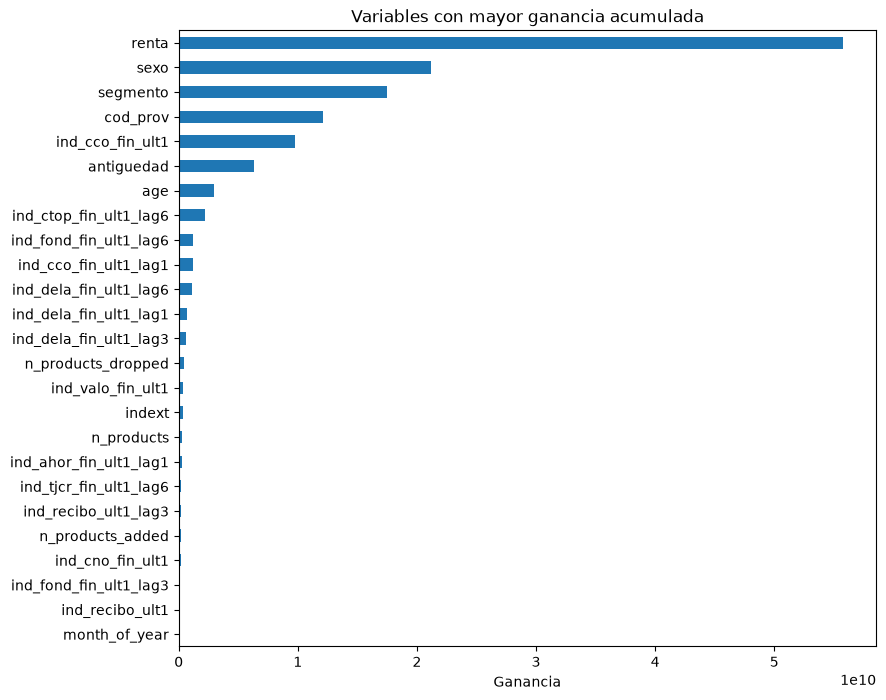

In [14]:
comparison = pd.DataFrame({
    "corte": ["Validacion marzo (objetivo abril)", "Prueba abril (objetivo mayo)"],
    "popularidad_MAP@7": [map_at_7(valid, valid_pop), map_at_7(test, test_pop)],
    "LightGBM_MAP@7": [map_at_7(valid, valid_model), map_at_7(test, test_model)],
})
display(comparison)

importance_df = pd.DataFrame(importance)
if not importance_df.empty:
    top = importance_df.groupby("feature", as_index=False).gain.sum().nlargest(25, "gain")
    display(top)
    ax = top.sort_values("gain").plot.barh(x="feature", y="gain", figsize=(9, 8), legend=False)
    ax.set_title("Variables con mayor ganancia acumulada")
    ax.set_xlabel("Ganancia")
    ax.set_ylabel("")


### **8. Entrenar el modelo final de prueba y recomendar**

Para recomendar a partir de mayo, los modelos finales incorporan filas hasta marzo (etiquetas observadas hasta abril). El resultado de mayo predice junio y no tiene MAP@7 porque no existe la etiqueta del mes siguiente.

In [15]:
print("---")

final_train = labeled.loc[(labeled.fecha_dato >= "2015-07-28") & (labeled.fecha_dato <= "2016-03-28")].copy()
may_scores = pd.DataFrame(0.0, index=may.index, columns=products)
final_models = {}

for p in products:
    label = f"{LABEL_PREFIX}{p}"
    tr = final_train.loc[final_train[p].fillna(0).eq(0)]
    pred_rows = may.loc[may[p].fillna(0).eq(0)]
    if tr[label].nunique() < 2 or pred_rows.empty:
        continue
    Xtr, Xpred = tr[feature_cols].copy(), pred_rows[feature_cols].copy()
    cat_cols = Xtr.select_dtypes(include=["object", "string", "category"]).columns.tolist()
    for col in cat_cols:
        Xtr[col] = Xtr[col].astype("category")
        Xpred[col] = align_categories(Xpred[col], Xtr[col].cat.categories)
    n_trees = max(20, models[p].best_iteration_) if p in models else 200
    final_model = lgb.LGBMClassifier(
        objective="binary", n_estimators=n_trees, learning_rate=0.05,
        num_leaves=31, subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbosity=-1,
    )
    final_model.fit(Xtr, tr[label].astype("int8"), categorical_feature=cat_cols or "auto")
    final_models[p] = final_model
    may_scores.loc[pred_rows.index, p] = final_model.predict_proba(Xpred)[:, 1]

client_id = int(may["ncodpers"].iloc[0])
row = may.loc[may.ncodpers == client_id].iloc[0]
held = {p for p in products if pd.notna(row[p]) and row[p] == 1}
ranked = sorted(products, key=lambda p: (-float(may_scores.at[row.name, p]), p))
recommendations = [(p, float(may_scores.at[row.name, p])) for p in ranked if p not in held][:K]
print(f"Cliente de ejemplo: {client_id} | recomendaciones para junio (muestra)")
display(pd.DataFrame(recommendations, columns=["producto", "propension"]))


---
Cliente de ejemplo: 16556 | recomendaciones para junio (muestra)


,producto,propension
0,ind_cco_fin_ult1,0.001345
1,ind_ecue_fin_ult1,0.000880
2,ind_ctma_fin_ult1,0.000275
3,ind_nom_pens_ult1,0.000207
4,ind_reca_fin_ult1,0.000195
5,ind_tjcr_fin_ult1,0.000140
6,ind_ctop_fin_ult1,0.000133


### **9. Guardar el artefacto local**

Guarda los modelos, las features y los resultados de la prueba para integrarlos después en la API. Esto guarda solo el artefacto de modelo, no una copia local del dataset.

In [16]:
import joblib

artifact_path = Path("data/models/finsir_lightgbm_sample10.joblib")
artifact_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({
    "models": final_models,
    "feature_cols": feature_cols,
    "products": products,
    "sample_rule": f"hash(ncodpers) % {SAMPLE_MODULUS} = 0",
    "training_max_feature_month": "2016-03-28",
    "validation_map_at_7": map_at_7(valid, valid_model),
    "test_map_at_7": map_at_7(test, test_model),
}, artifact_path)
print("Artefacto:", artifact_path)


Artefacto: data\models\finsir_lightgbm_sample10.joblib
